# 01 · Exploratory data analysis

**Task T09 (M3).** This notebook checks the dataset facts the plan assumed (Section 6), fixes the
maximum token lengths the models use (Section 7), and previews the shortcuts and duplicates that
T13 deals with. Every dataset is loaded through the package (`factcheck.data.load_splits`), so
this notebook sees exactly what training sees; no loader code is copied here.

Run it top to bottom from a fresh kernel. It needs the raw data
(`python scripts/download_data.py`) and, for the retrieval check in Section 8, the T08 claim
embeddings (`python -m factcheck.retrieval build --datasets covid liar pubhealth isot`; on a
CPU, ISOT takes about half an hour). Figures are saved to `results/figures/eda_*.png` for the
slides.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from factcheck.data import dataset_names, get_dataset, load_splits
from factcheck.paths import FIGURES_DIR

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_colwidth", 140)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

NAMES = dataset_names()  # covid, liar, pubhealth, isot, climate_fever
data = {name: load_splits(name) for name in NAMES}  # what training uses (T13 exclusions dropped)
full = {name: load_splits(name, drop_excluded=False) for name in NAMES}  # the committed split


def stack(splits: dict) -> pd.DataFrame:
    # All splits in one frame with a "split" column, rows numbered 0..n-1.
    df = pd.concat(splits.values(), keys=splits.keys(), names=["split", None])
    return df.reset_index(level=0).reset_index(drop=True)


everything = {name: stack(s) for name, s in data.items()}


def save(fig, name: str) -> None:
    path = FIGURES_DIR / f"eda_{name}.png"
    fig.savefig(path, bbox_inches="tight")
    print(f"saved {path.relative_to(FIGURES_DIR.parents[1])}")

## 1. Dataset sizes

Rows per split, next to the sizes quoted in plan Section 6. *train (split)* is the committed split; *train used* is what models train on after T13 drops training rows that copy a validation/test row.

In [2]:
PLAN = {  # plan Section 6 (train, validation, test); ISOT's 44,898 is before our split
    "covid": (6420, 2140, 2140), "liar": (10269, 1284, 1283),
    "pubhealth": (9800, 1200, 1200), "isot": None, "climate_fever": (0, 0, 1535),
}
rows = []
for name, splits in data.items():
    split_train = len(full[name]["train"])
    rows.append({
        "dataset": name, "train (split)": split_train,
        "excluded by T13": split_train - len(splits["train"]), "train used": len(splits["train"]),
        "validation": len(splits["validation"]), "test": len(splits["test"]),
        "plan total": "44,898 raw" if PLAN[name] is None else f"{sum(PLAN[name]):,}",
        "classes": get_dataset(name).num_labels,
    })
sizes = pd.DataFrame(rows).set_index("dataset")
sizes

,train (split),excluded by T13,train used,validation,test,plan total,classes
dataset,,,,,,,
covid,6420,410,6010,2140,2140,"10,700",2
liar,10269,59,10210,1284,1283,"12,836",6
pubhealth,9804,27,9777,1214,1233,"12,200",4
isot,30926,335,30591,3866,3866,"44,898 raw",2
climate_fever,0,0,0,0,1535,"1,535",4


**What this shows.** All five datasets load with the sizes the papers report, and validation and test are exactly the official splits. The gaps are deliberate. PUBHEALTH drops 41 broken rows with label -1 (T03). ISOT keeps 38,658 of 44,898 articles after removing empty bodies and exact duplicates (T03; see `docs/m3_isot_and_splits.md`). T13 then excludes training rows that copy a validation/test row: 410 COVID (6.4%), 59 LIAR, 27 PUBHEALTH and 335 ISOT.

## 2. Label balance

saved results\figures\eda_label_balance.png


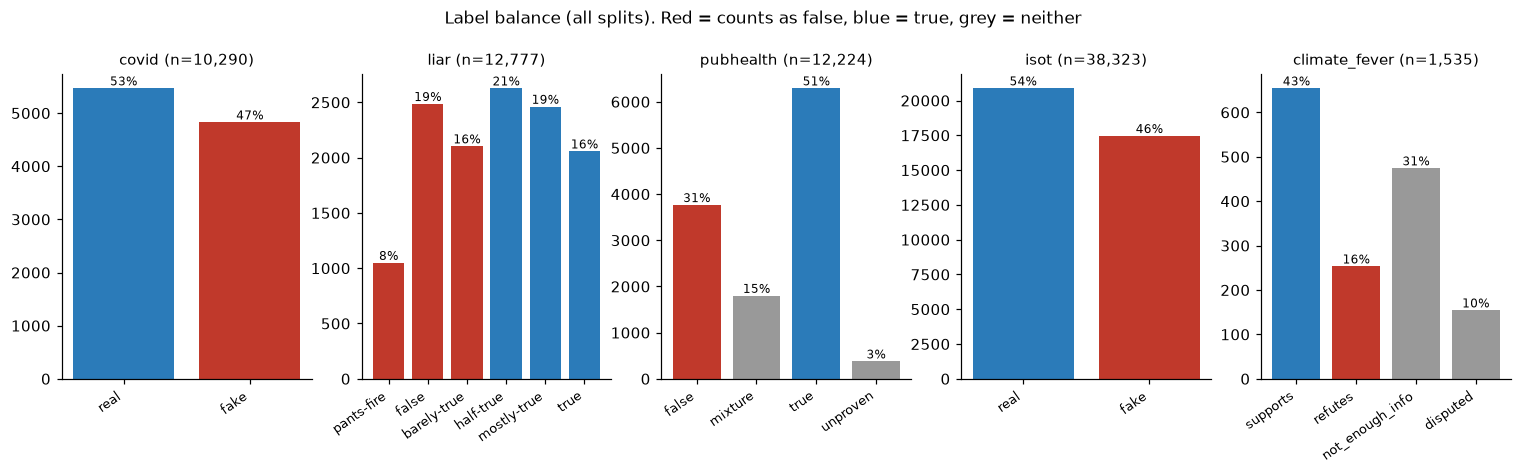

,covid,liar,pubhealth,isot,climate_fever
label_name,,,,,
barely-true,,0.165,,,
disputed,,,,,0.1
fake,0.469,,,0.455,
false,,0.194,0.308,,
half-true,,0.206,,,
mixture,,,0.147,,
mostly-true,,0.193,,,
not_enough_info,,,,,0.309
pants-fire,,0.082,,,


In [3]:
fig, axes = plt.subplots(1, len(NAMES), figsize=(17, 3.6))
for ax, name in zip(axes, NAMES):
    info = get_dataset(name)
    counts = everything[name]["label_name"].value_counts().reindex(info.labels, fill_value=0)
    colors = ["#c0392b" if lab in info.fake_labels else "#2b7bb9" if lab in info.real_labels
              else "#999999" for lab in info.labels]
    ax.bar(range(len(counts)), counts.values, color=colors)
    ax.set_xticks(range(len(counts)), counts.index, rotation=35, ha="right", fontsize=8.5)
    ax.set_title(f"{name} (n={counts.sum():,})", fontsize=10)
    for i, v in enumerate(counts.values):
        ax.text(i, v, f"{v / counts.sum():.0%}", ha="center", va="bottom", fontsize=8)
fig.suptitle("Label balance (all splits). Red = counts as false, blue = true, grey = neither",
             fontsize=11, y=1.04)
save(fig, "label_balance")
plt.show()

balance = pd.DataFrame({
    name: everything[name]["label_name"].value_counts(normalize=True).round(3)
    for name in NAMES
}).fillna("")
balance

**What this shows.** COVID and ISOT are close to balanced (47% and 45% fake), so accuracy means something there. LIAR's six classes are fairly even apart from pants-fire (8%). PUBHEALTH is skewed: true 51%, false 31%, mixture 15%, unproven only 3%. A model that always answers "true" already gets 52% accuracy on validation, which is why macro-F1 is the main metric and why the plan uses a class-weighted loss for LIAR and PUBHEALTH (E5). Climate-FEVER is only a test set; its "supports" and "refutes" claims are the ones the cross-domain tests (E8) map to true and false.

## 3. Token lengths and the maximum lengths

Each text is tokenised with the DeBERTa-v3 and RoBERTa tokenizers (including special tokens).
PUBHEALTH and Climate-FEVER are also measured as *claim + 5 evidence sentences*, the input of
the evidence runs. For Climate-FEVER these are the claim's 5 given sentences. For PUBHEALTH
the retriever (T08) picks 5 sentences of the claim's fact-check article; here we take the
article's **5 longest** sentences instead, an upper bound on whatever the retriever picks, so
the max-length decision holds for any top-5 (and this cell needs no embeddings).
The dashed line is the planned maximum length.

In [4]:
from transformers import AutoTokenizer

from factcheck.retrieval import split_sentences

TOKENIZERS = {
    "DeBERTa-v3": AutoTokenizer.from_pretrained("microsoft/deberta-v3-base"),
    "RoBERTa": AutoTokenizer.from_pretrained("roberta-base"),
}
PLANNED = {"covid": 128, "liar": 128, "pubhealth": 128, "pubhealth + 5 longest sentences": 384,
           "isot": 512, "climate_fever": 128, "climate_fever + 5 evidence": 384}


def five_longest(article: str) -> str:
    return " ".join(sorted(split_sentences(article), key=len, reverse=True)[:5])


inputs = {name: (everything[name]["text"].tolist(), None) for name in NAMES}
pubhealth, climate = everything["pubhealth"], everything["climate_fever"]
inputs["pubhealth + 5 longest sentences"] = (pubhealth["text"].tolist(),
                                             pubhealth["main_text"].map(five_longest).tolist())
inputs["climate_fever + 5 evidence"] = (climate["text"].tolist(),
                                        climate["evidence"].map(" ".join).tolist())

lengths = {}
for tok_name, tok in TOKENIZERS.items():
    for name, (first, second) in inputs.items():
        enc = tok(first, second) if second is not None else tok(first)
        lengths[tok_name, name] = np.array([len(ids) for ids in enc["input_ids"]])

rows = []
for (tok_name, name), n in lengths.items():
    rows.append({"input": name, "tokenizer": tok_name, "p50": int(np.percentile(n, 50)),
                 "p95": int(np.percentile(n, 95)), "p99": int(np.percentile(n, 99)),
                 "max": int(n.max()), "planned max": PLANNED[name],
                 "% truncated": round(100 * (n > PLANNED[name]).mean(), 1)})
token_table = pd.DataFrame(rows).set_index(["input", "tokenizer"])
token_table

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1879 > 512). Running this sequence through the model will result in indexing errors


,,p50,p95,p99,max,planned max,% truncated
input,tokenizer,,,,,,
covid,DeBERTa-v3,46,90,113,2779,128,0.2
liar,DeBERTa-v3,22,41,50,96,128,0.0
pubhealth,DeBERTa-v3,16,39,53,98,128,0.0
isot,DeBERTa-v3,459,1082,1605,9715,512,39.5
climate_fever,DeBERTa-v3,25,48,60,80,128,0.0
pubhealth + 5 longest sentences,DeBERTa-v3,250,479,676,1386,384,11.7
climate_fever + 5 evidence,DeBERTa-v3,189,291,366,1191,384,0.7
covid,RoBERTa,47,94,122,2758,128,0.4
liar,RoBERTa,23,41,51,93,128,0.0


saved results\figures\eda_token_lengths.png


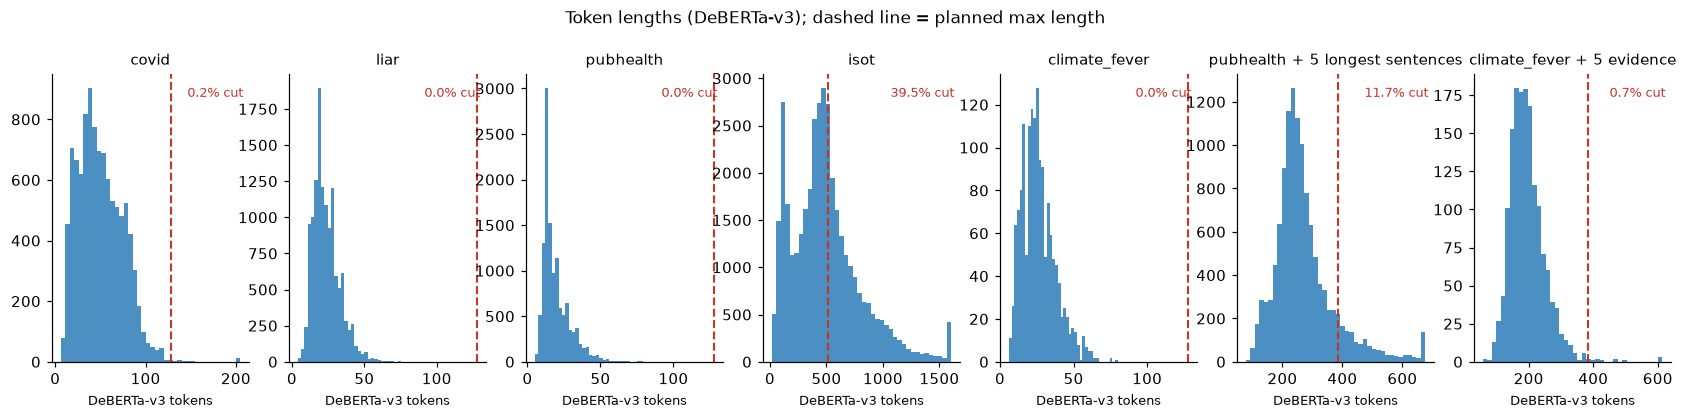

In [5]:
fig, axes = plt.subplots(1, len(inputs), figsize=(19, 3.4))
for ax, name in zip(axes, inputs):
    n = lengths["DeBERTa-v3", name]
    upper = max(PLANNED[name] * 1.6, np.percentile(n, 99))
    ax.hist(np.clip(n, 0, upper), bins=40, color="#2b7bb9", alpha=0.85)
    ax.axvline(PLANNED[name], color="#c0392b", ls="--", lw=1.4)
    ax.set_title(name, fontsize=9.5)
    ax.set_xlabel("DeBERTa-v3 tokens", fontsize=8.5)
    ax.text(0.97, 0.92, f"{(n > PLANNED[name]).mean():.1%} cut", transform=ax.transAxes,
            ha="right", fontsize=8.5, color="#c0392b")
fig.suptitle("Token lengths (DeBERTa-v3); dashed line = planned max length", fontsize=11, y=1.05)
save(fig, "token_lengths")
plt.show()

**What this shows.** The planned maximum lengths hold. COVID posts fit in 128 tokens (99th percentile 113; 0.2% are cut), and LIAR statements and PUBHEALTH claims are far shorter (99th percentile 50 and 53) and are never cut. ISOT articles are long (median 459 tokens) and 39.5% are longer than 512, so the head 128 + tail 382 cut really matters; ModernBERT's 8,192-token context could read them whole.

Claim + evidence: even the upper bound for PUBHEALTH (claim + the article's 5 longest sentences) has a median of 250 tokens and fits in 384 for 88% of claims, so at most 12% of real inputs lose part of their evidence. The tokenizer should cut only the evidence (`truncation="only_second"`), and since the retriever lists the most similar sentence first, what gets cut is the least relevant one. Climate-FEVER's claim + 5 evidence sentences fit for 99.3% of claims. DeBERTa-v3 and RoBERTa differ by only a few percent.

## 4. Duplicates

Exact duplicates after normalising the text (lower-case, punctuation and spaces removed), within
each split and across splits. Cross-split duplicates are the dangerous kind: the model is
tested on a text it was trained on. T13 removes them (from train, never from test) and also
looks for *near* duplicates with the T08 embeddings.

In [6]:
from factcheck.data.leakage import normalise  # lower-case; links and punctuation removed


def test_rows_seen_in_train(df: pd.DataFrame) -> int:
    seen = set(df.loc[df["split"] == "train", "norm"])
    return int((df["split"].eq("test") & df["norm"].isin(seen)).sum())


rows = []
for name in NAMES:
    before = stack(full[name]).assign(norm=lambda d: d["text"].map(normalise))
    after = everything[name].assign(norm=lambda d: d["text"].map(normalise))
    within = sum(int(g["norm"].duplicated().sum()) for _, g in before.groupby("split"))
    conflicts = int((before.groupby("norm")["label"].nunique() > 1).sum())
    rows.append({"dataset": name, "rows": len(before), "duplicates within a split": within,
                 "same text, different labels": conflicts,
                 "test rows also in train: split": test_rows_seen_in_train(before),
                 "test rows also in train: after T13": test_rows_seen_in_train(after)})
dupes = pd.DataFrame(rows).set_index("dataset")
dupes

,rows,duplicates within a split,"same text, different labels",test rows also in train: split,test rows also in train: after T13
dataset,,,,,
covid,10700,135,0,93,0
liar,12836,22,7,5,0
pubhealth,12251,8,4,2,0
isot,38658,178,0,49,0
climate_fever,1535,46,16,0,0


In [7]:
from factcheck.retrieval import DUPLICATE_FLAGS_CSV, DUPLICATE_THRESHOLD

near = pd.read_csv(DUPLICATE_FLAGS_CSV) if DUPLICATE_FLAGS_CSV.exists() else pd.DataFrame()
if near.empty:
    print("No T08 duplicate flags yet: run python -m factcheck.retrieval check")
else:
    print(f"Validation/test claims whose nearest TRAIN claim has cosine similarity >= "
          f"{DUPLICATE_THRESHOLD} (T08 flags, handed to T13):")
    display(near.groupby(["dataset", "split"]).size().unstack(fill_value=0))
    display(near.sort_values("similarity").head(3)[["dataset", "label_name", "train_label_name",
                                                     "similarity", "text", "train_text"]])

Validation/test claims whose nearest TRAIN claim has cosine similarity >= 0.97 (T08 flags, handed to T13):


split,test,validation
dataset,,
covid,265,231
isot,71,61
liar,7,9
pubhealth,6,1


,dataset,label_name,train_label_name,similarity,text,train_text
235,covid,real,real,0.9701,681 new cases of #COVID19; Lagos-345 Rivers-51 Ogun-48 Gombe-47 Oyo-36 Imo-31 Delta-28 Kano-23 Bauchi-18 Edo-12 Katsina-12 Kaduna-9 Anam...,315 new cases of #COVID19; Lagos- 128 FCT-34 Rivers- 32 Edo- 28 Oyo- 22 Kaduna- 20 Gombe- 13 Ogun- 8 Plateau- 5 Delta- 7 Kwara- 7 Kano- ...
351,covid,real,real,0.9701,As at 09:30 pm 5th April there are 232 confirmed cases 33 discharged 5 deaths For a breakdown of cases by state- https://t.co/zQrpNf5Q61...,As at 09:30 pm 6th April there are 238 confirmed cases 35 discharged 5 deaths For a breakdown of cases by state- https://t.co/zQrpNeOfet...
37,covid,fake,fake,0.9701,A team of medical trainees from JKUAT (a university in Kenya) have developed and tested a vaccine successfully.,_A team of medical trainees from JKUAT (a university in Kenya) have developed and tested a vaccine successfully._


**What this shows.** Before T13, 93 COVID, 49 ISOT, 5 LIAR and 2 PUBHEALTH test rows had the same text (after normalising) as a training row, so a model could be graded on a text it had memorised. After T13's exclusions there are none. Repeats inside one split are rare (at most 1.3% of a dataset, except Climate-FEVER: 46 of 1,535 claims, 3%). A few texts carry two different labels (LIAR 7, PUBHEALTH 4, Climate-FEVER 16): the same claim fact-checked twice with different verdicts, which no model can get right both times.

The T08 flags are much wider (embedding similarity >= 0.97: 496 COVID posts). The closest of them show why T13 does not exclude them all: many are templated updates that report different numbers, such as "681 new cases" against "315 new cases". Those are different facts, not copies, so T13 only excludes near-copies that also state the same numbers.

## 5. Examples

Two random rows per label, so everyone can see what each task looks like.

In [8]:
for name in NAMES:
    df = everything[name]
    sample = df.groupby("label_name").sample(n=2, random_state=1)
    sample = sample.assign(text=sample["text"].str.slice(0, 220))
    print(f"\n{name}")
    display(sample[["split", "label_name", "text"]].reset_index(drop=True))


covid


,split,label_name,text
0,train,fake,We will not allow this pandemic to rob our young people of the futures and the economic opportunities they have been working to build. h...
1,train,fake,In the Philippines Kabataan Partylist representative Sarah Elago is shown in a quote card saying the lockdown amid the COVID-19 pandemic...
2,validation,real,There's been a lot of discussions about deaths continuing to trend down as cases have surged. This chart provides a partial answer to wh...
3,validation,real,As of today there are 189 total confirmed #COVID19 cases and 129 active #COVID_19 cases in #Srikakulam #AndhraPradesh: https://t.co/X0dk...



liar


,split,label_name,text
0,train,barely-true,"For the first time in history, (Thors) hammer is being held by a woman."
1,train,barely-true,Congresswoman Frederica Wilson successfully postpones closure of the North Perry airport tower.
2,train,false,"In 1916, the U.S. government predicted that by the 1940s all paper would come from hemp and that no more trees would need to be cut down."
3,train,false,On support for the Bridge to Nowhere.
4,test,half-true,We have never done business with Donald Trump.
5,train,half-true,"As a result of the House Republican bill, the nonpartisan Congressional Budget Office now confirms that families will see their health c..."
6,train,mostly-true,Says Rep. Paul Ryans budget roadmap doesnt balance the budget until the 2060s and adds an unthinkable $62 trillion to the national debt ...
7,test,mostly-true,The education tax burden for Shelby County -- and Tennessee -- is one of the lowest in the country.
8,train,pants-fire,"Oregon Rep. Tina Kotek, D-Portland, has never held a job nor run a business"
9,validation,pants-fire,"""The president is brain-dead."""



pubhealth


,split,label_name,text
0,train,false,Suggests the flu shot was responsible for the death of a New York state senator.
1,train,false,Spironolactone may be an alternative to antibiotics in women's acne treatment
2,validation,mixture,FDA Clears P-Cure Upright Imaging Solution for Proton Therapy Enhancement
3,train,mixture,A photograph shows an improperly displayed American flag outside of a Quality Inn hotel in May 2019.
4,validation,true,"A video shows a chicken being hypnotized by holding its head down and ""drawing"" a line in the sand extending from its beak."
5,train,true,Gene raises risk of lifetime smoking habit: study.
6,train,unproven,Hanging plastic bags filled with water will repel flies.
7,train,unproven,Bones found on the remote Pacific Island of Nikumaroro belong to famed aviator Amelia Earhart.



isot


,split,label_name,text
0,train,fake,Disabled Man Confronts Ted Cruz For His Lies About Obamacare (VIDEO). Republican presidential hopeful and Texas senator Ted Cruz has ear...
1,train,fake,Even Foreign Leaders Are Responding To Charlottesville Better Than Trump Did. After a night of white supremacist marches in Charlottesvi...
2,train,real,"Afghan civilian casualties from air strikes rise more than 50 percent, says U.N.. KABUL (Reuters) - Civilian casualties from Afghan and ..."
3,train,real,EU eyes more self-reliance after Trump victory. BRUSSELS (Reuters) - The European Union must take responsibility for dealing with neighb...



climate_fever


,split,label_name,text
0,test,disputed,Clouds provide negative feedback.
1,test,disputed,"The team of climate scientists notes that in failing to predict the warming 'hiatus' in the beginning of the 21st century, the Intergove..."
2,test,not_enough_info,"temperatures rise and they fall, and they rise and they fall… and for the last 400 years we've had a gentle warming as we've been coming..."
3,test,not_enough_info,Solar Cycle Length proves its the sun.
4,test,refutes,"The lower temperatures at this ""coldest point"" have caused global water vapor levels to drop, even as carbon levels rise."
5,test,refutes,"Human-produced carbon might be one of the factors of climate change, but there's simply no evidence that it is a significant one."
6,test,supports,"The most interesting thing here is that the albedo forcings, in watts/sq meter seem to be fairly large."
7,test,supports,"This is called the ""atmospheric greenhouse effect"", and without it the Earth's surface would be much colder."


## 6. ISOT shortcut preview

ISOT's real articles come from Reuters and its fake articles from other sites, so the source
leaves fingerprints. A model can learn those instead of the content. This previews the two
best-known cues; T13 removes the in-text ones and M4's shortcut study (E7, T34) measures their
effect.

saved results\figures\eda_isot_shortcuts.png


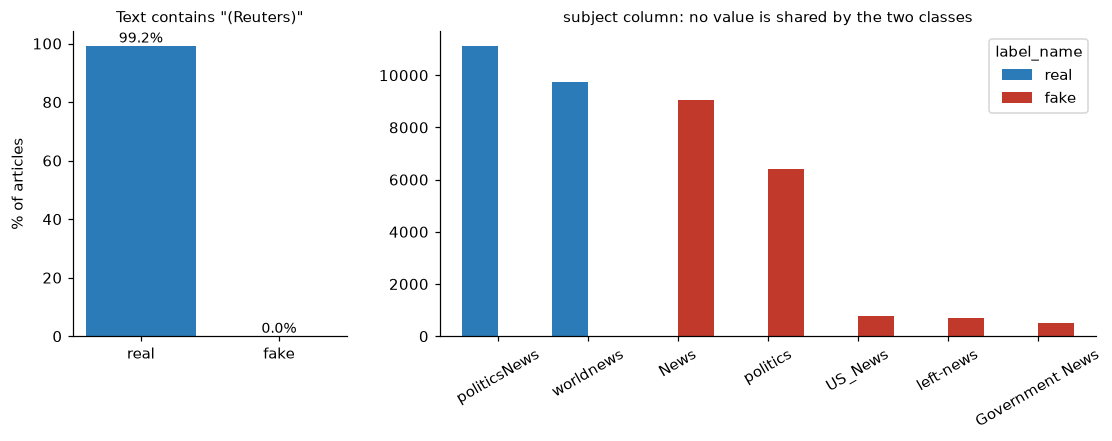

,share with (Reuters)
label_name,
real,0.9922
fake,0.0004


In [9]:
isot = everything["isot"]
reuters = isot.groupby("label_name")["text"].apply(
    lambda s: s.str.contains("(Reuters)", regex=False).mean()).reindex(["real", "fake"])
subjects = pd.crosstab(isot["subject"], isot["label_name"])[["real", "fake"]]
subjects = subjects.sort_values(["real", "fake"], ascending=False)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1, 2.4]})
ax1.bar(reuters.index, reuters.values * 100, color=["#2b7bb9", "#c0392b"])
for i, v in enumerate(reuters.values):
    ax1.text(i, v * 100, f"{v:.1%}", ha="center", va="bottom", fontsize=9)
ax1.set_ylabel("% of articles")
ax1.set_title('Text contains "(Reuters)"', fontsize=10)
subjects.plot.bar(ax=ax2, color=["#2b7bb9", "#c0392b"], width=0.8)
ax2.set_title("subject column: no value is shared by the two classes", fontsize=10)
ax2.set_xlabel("")
ax2.tick_params(axis="x", rotation=30)
save(fig, "isot_shortcuts")
plt.show()
reuters.round(4).to_frame("share with (Reuters)")

**What this shows.** 99% of real ISOT articles contain "(Reuters)" and almost no fake ones do, and not one `subject` value is shared by the two classes. Either cue alone separates the classes almost perfectly without reading the claim. So `subject` is never model input, and T13's `clean` variant removes the Reuters dateline and the other collection fingerprints (rule table in `docs/m3_retrieval_and_shortcuts.md`). E7 compares models trained on raw and on clean text.

## 7. LIAR metadata coverage

Share of LIAR statements with each metadata field missing (the T15 metadata prefix writes `unknown` for these).

saved results\figures\eda_liar_metadata.png


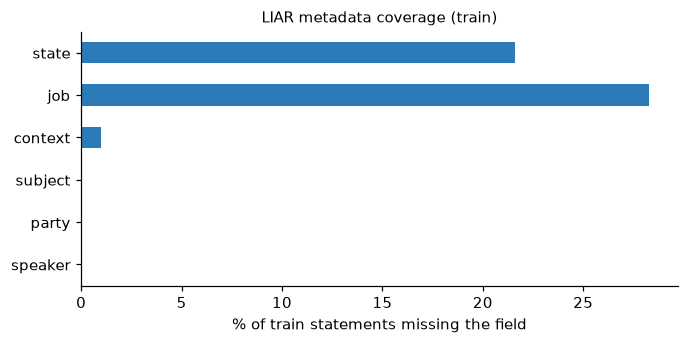

,train,validation,test
speaker,0.000,0.000,0.000
party,0.000,0.000,0.000
subject,0.000,0.000,0.000
context,0.010,0.009,0.013
job,0.283,0.269,0.256
state,0.216,0.217,0.206


In [10]:
liar = everything["liar"]
meta_cols = [c for c in liar.columns if c.startswith("meta_")]
missing = pd.DataFrame({
    split: liar.loc[liar["split"] == split, meta_cols].apply(
        lambda s: s.fillna("").str.strip().eq("").mean())
    for split in ("train", "validation", "test")
}).round(3)
missing.index = [c.removeprefix("meta_") for c in missing.index]

fig, ax = plt.subplots(figsize=(7, 3))
(missing["train"] * 100).plot.barh(ax=ax, color="#2b7bb9")
ax.set_xlabel("% of train statements missing the field")
ax.set_title("LIAR metadata coverage (train)", fontsize=10)
save(fig, "liar_metadata")
plt.show()
missing

**What this shows.** Speaker, party and subject are always present and context is missing for only 1% of statements, so the T15 metadata prefix has something to add for almost every claim. Job title (28% missing) and state (22% missing) are patchier; the prefix writes `unknown` for them.

## 8. Does retrieval carry signal? (T08 check)

The kNN vote labels each validation claim with the similarity-weighted majority verdict of its
8 nearest training claims. It costs nothing to train, so it is a floor every model should beat,
and it shows whether "similar past fact-checks" (the LLM's retrieval mode) are informative.

In [11]:
from sklearn.metrics import accuracy_score, f1_score

from factcheck.retrieval import embed_split, load_claim_index

rows = []
for name in ("covid", "liar", "pubhealth", "isot"):
    index, val = load_claim_index(name), data[name]["validation"]
    pred = index.vote(embed_split(index, val, "validation"), k=8).argmax(axis=1)
    rows.append({"dataset": name,
                 "majority-class accuracy": val["label"].value_counts(normalize=True).iloc[0],
                 "kNN accuracy": accuracy_score(val["label"], pred),
                 "kNN macro-F1": f1_score(val["label"], pred, average="macro")})
knn = pd.DataFrame(rows).set_index("dataset").round(3)
knn

,majority-class accuracy,kNN accuracy,kNN macro-F1
dataset,,,
covid,0.523,0.926,0.925
liar,0.205,0.272,0.268
pubhealth,0.518,0.619,0.435
isot,0.548,0.918,0.916


**What this shows.** The kNN vote beats the majority class on every dataset: COVID 0.926 against 0.523, ISOT 0.918 against 0.548, PUBHEALTH 0.619 against 0.518 and LIAR 0.272 against 0.205 (validation accuracy). PUBHEALTH's macro-F1 is only 0.435 because the vote seldom gets mixture and unproven right. Similar past fact-checks are informative, most of all on COVID, where many posts repeat an earlier claim or template, which supports the LLM's retrieval mode. ISOT's index uses the raw text, fingerprints included. Test scores are in `results/runs.csv` (run names `knn_bge_small_*`).

## 9. Decisions for the team

These go to M1 + M2 for the training configs.

| Decision | Value | Why (sections above) |
|---|---|---|
| Max length, COVID | 128 | 0.2% of posts are longer |
| Max length, LIAR | 128 | longest statement is 96 tokens |
| Max length, PUBHEALTH and Climate-FEVER claim only | 128 | longest claims are 104 and 80 tokens |
| Max length, PUBHEALTH claim + evidence | 384, truncate the evidence only | upper bound fits for 88%; the least relevant sentence is cut first |
| Max length, Climate-FEVER claim + evidence | 384 | fits for 99.3% |
| Max length, ISOT | 512 as head 128 + tail 382 | 39.5% of articles are longer than 512 |
| Class-weighted loss | LIAR and PUBHEALTH | pants-fire is 8% of LIAR; unproven 3% and mixture 15% of PUBHEALTH |
| Main metric | macro-F1 | always answering "true" scores 52% on PUBHEALTH validation |
| ISOT input | `variant: clean`; never `subject` or `date` | Section 6 and T13 |
| Leakage | nothing to do | T13's exclusions are applied by `load_splits` |

Lowering the maximum for the short datasets would not make training faster: the encoder code
pads each batch only to its longest text, so the maximum only decides what gets cut.